Checking label 0
Checking label 1
Checking label 10
Checking label 11
Checking label 2
Checking label 3
Checking label 4
Checking label 5
Checking label 6
Checking label 7
Checking label 8
Checking label 9


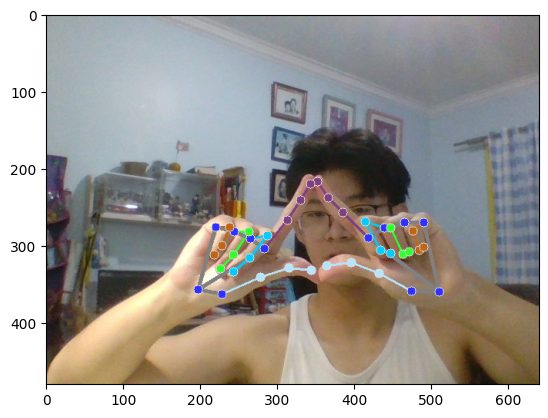

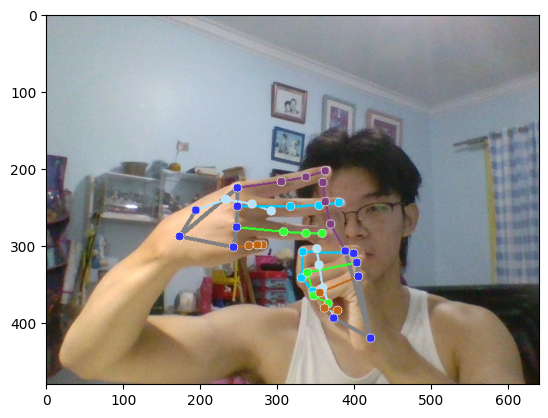

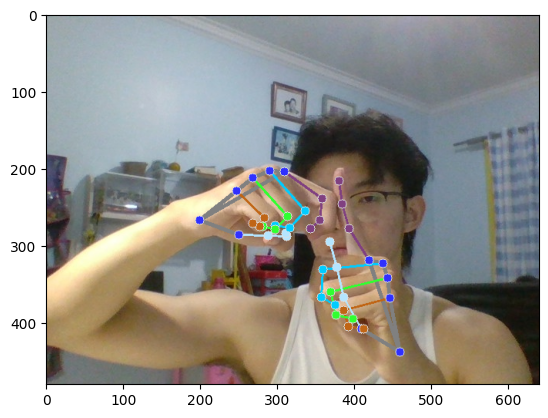

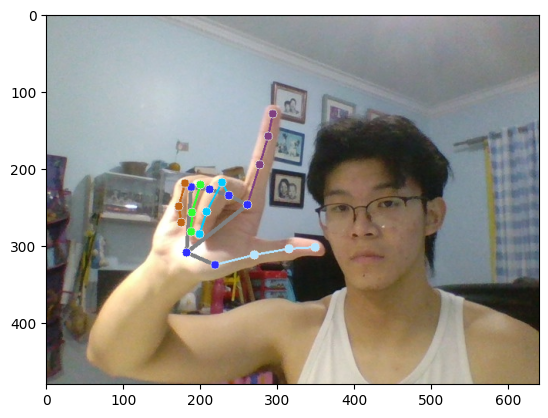

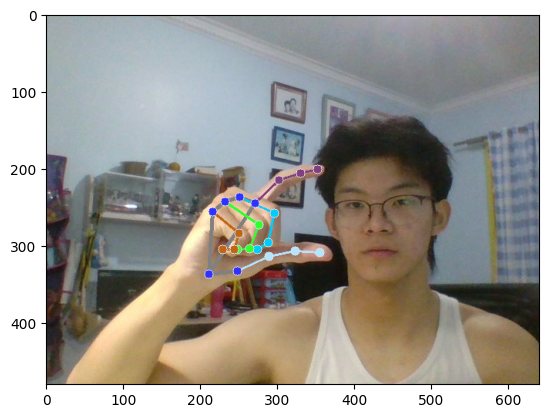

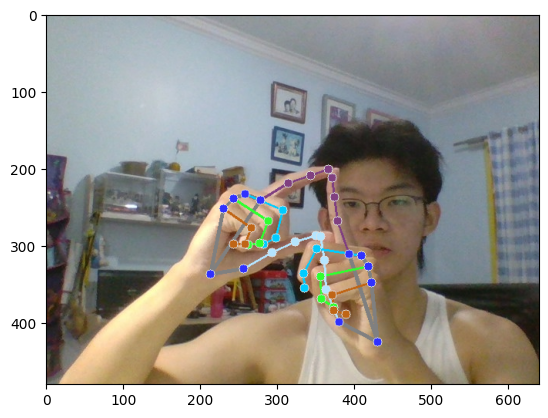

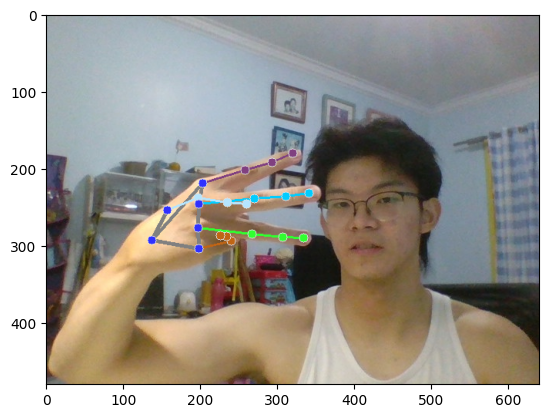

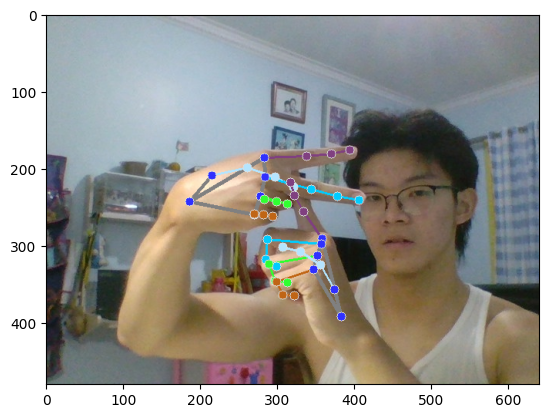

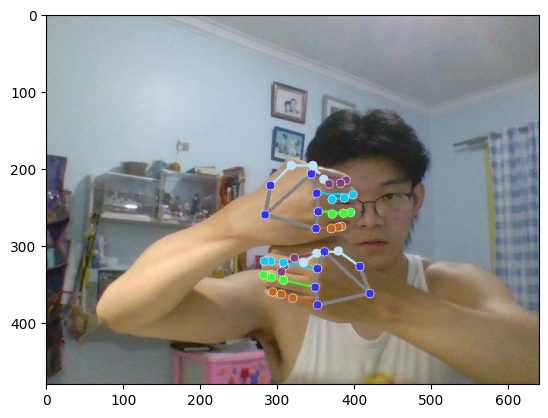

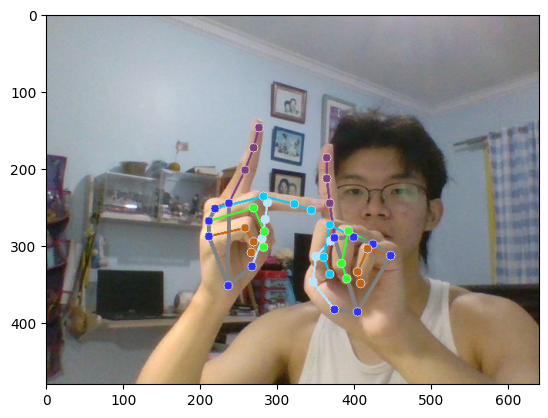

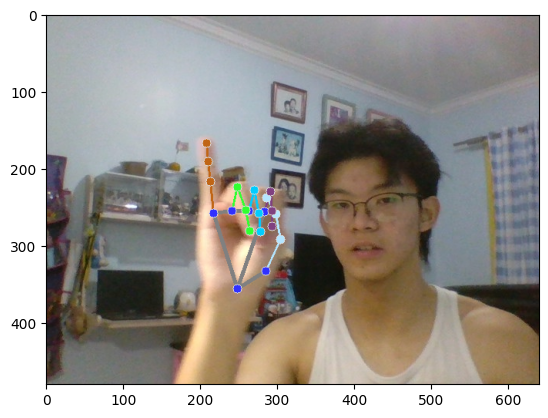

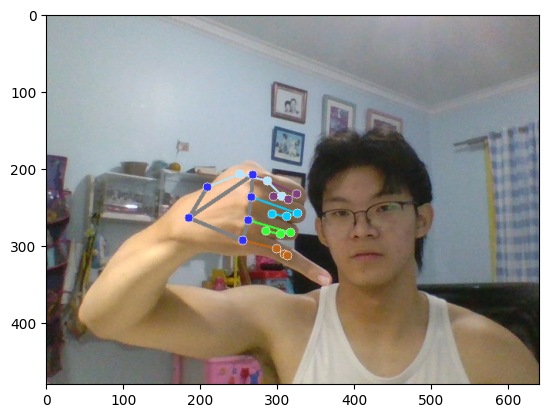

In [7]:
import os
import pickle

import mediapipe as mp
import cv2
import matplotlib.pyplot as plt


mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils
mp_drawing_styles = mp.solutions.drawing_styles

hands = mp_hands.Hands(
    static_image_mode=True, 
    min_detection_confidence=0.1, 
    max_num_hands=2
    )

DATA_DIR = './data_v1'

for dir_ in os.listdir(DATA_DIR):
    print(f'Checking label {dir_}')
    for img_path in os.listdir(os.path.join(DATA_DIR, dir_)):
        img = cv2.imread(os.path.join(DATA_DIR, dir_, img_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        results = hands.process(img_rgb)
        if results.multi_hand_landmarks:
            for hand_landmarks in results.multi_hand_landmarks:
                mp_drawing.draw_landmarks(
                    img_rgb,
                    hand_landmarks,
                    mp_hands.HAND_CONNECTIONS,
                    mp_drawing_styles.get_default_hand_landmarks_style(),
                    mp_drawing_styles.get_default_hand_connections_style()
                )
        plt.figure()
        plt.imshow(img_rgb)
        #just show first image in each class
        break
